In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv("retail_store_sales.csv")
print("dataset loaded successfully !")

dataset loaded successfully !


In [23]:
df

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False
...,...,...,...,...,...,...,...,...,...,...,...
12570,TXN_9347481,CUST_18,Patisserie,Item_23_PAT,38.0,4.0,152.0,Credit Card,In-store,2023-09-03,NaN
12571,TXN_4009414,CUST_03,Beverages,Item_2_BEV,6.5,9.0,58.5,Cash,Online,2022-08-12,False
12572,TXN_5306010,CUST_11,Butchers,Item_7_BUT,14.0,10.0,140.0,Cash,Online,2024-08-24,NaN
12573,TXN_5167298,CUST_04,Furniture,Item_7_FUR,14.0,6.0,84.0,Cash,Online,2023-12-30,True


In [5]:
print("Dataset Shape :" , df.shape)

print("\nColumns: ")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\n MIssing values :")
print(df.isnull().sum())

print("\nDuplicate rows: "  , df.duplicated().sum())

print("\n\n__________Statistical Summary__________")
df.describe(include = "all")

Dataset Shape : (12575, 11)

Columns: 
['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date', 'Discount Applied']

Data Types:
Transaction ID       object
Customer ID          object
Category             object
Item                 object
Price Per Unit      float64
Quantity            float64
Total Spent         float64
Payment Method       object
Location             object
Transaction Date     object
Discount Applied     object
dtype: object

 MIssing values :
Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64

Duplicate rows:  0


__________Statistical Summary__________


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
count,12575,12575,12575,11362,11966.000000,11971.000000,11971.000000,12575,12575,12575,8376
unique,12575,25,8,200,NaN,NaN,NaN,3,2,1114,2
top,TXN_6867343,CUST_05,Electric household essentials,Item_2_BEV,NaN,NaN,NaN,Cash,Online,2022-05-30,True
freq,1,544,1591,126,NaN,NaN,NaN,4310,6354,26,4219
mean,NaN,NaN,NaN,NaN,23.365912,5.536380,129.652577,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,10.743519,2.857883,94.750697,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,5.000000,1.000000,5.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,14.000000,3.000000,51.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,23.000000,6.000000,108.500000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,33.500000,8.000000,192.000000,NaN,NaN,NaN,NaN


In [25]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove unnecessary spaces from column names
df_clean.columns = df_clean.columns.str.strip()

# Convert Date column to datetime
df_clean["Transaction Date"] = pd.to_datetime(
    df_clean["Transaction Date"],
    errors="coerce"
)

# Clean text columns
text_columns = [
    "Item",
    "Category",
    "Payment Method",
    "Location",
    "Discount Applied"
]

for col in text_columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# Replace empty strings with missing values
df_clean = df_clean.replace(r"^\s*$", np.nan, regex=True)

# Convert numeric columns
numeric_columns = [
    "Price Per Unit",
    "Quantity",
    "Total Spent"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

# Fill missing Item values with Unknown
df_clean["Item"] = df_clean["Item"].fillna("Unknown")

# Fill missing numeric values using median
for col in numeric_columns:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

# Fill missing Discount Applied values
df_clean["Discount Applied"] = (
    df_clean["Discount Applied"].fillna("Unknown")
)

# Remove rows with invalid dates
df_clean = df_clean.dropna(subset=["Transaction Date"])

# Check cleaned dataset
print("Cleaned Dataset Shape:", df_clean.shape)
print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

Cleaned Dataset Shape: (12575, 11)

Missing Values After Cleaning:
Transaction ID      0
Customer ID         0
Category            0
Item                0
Price Per Unit      0
Quantity            0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
Discount Applied    0
dtype: int64


In [29]:
#calculating expected total spent
df_clean["Calculated Total"] = (
    df_clean["Price Per Unit"] * df_clean["Quantity"]
)

#comparing calculated and recorded total
df_clean["Total Mismatch"] = (
    df_clean["Total Spent"] - df_clean["Calculated Total"]
).abs() > 0.01

print("Records with Total Mismatch: ", df_clean["Total Mismatch"].sum())

Records with Total Mismatch:  1183


In [31]:
mismatched_records = df_clean[df_clean["Total Mismatch"]]

mismatched_records[[
    "Transaction ID",
    "Item",
    "Price Per Unit",
    "Quantity",
    "Total Spent",
    "Calculated Total",
    "Discount Applied"
]].head(10)

,Transaction ID,Item,Price Per Unit,Quantity,Total Spent,Calculated Total,Discount Applied
5,TXN_7482416,Unknown,23.0,10.0,200.0,230.0,Unknown
7,TXN_1372952,Unknown,33.5,6.0,108.5,201.0,True
11,TXN_5422631,Unknown,23.0,8.0,52.0,184.0,True
15,TXN_1809665,Unknown,24.5,6.0,108.5,147.0,Unknown
17,TXN_9634894,Unknown,23.0,10.0,275.0,230.0,Unknown
19,TXN_4206593,Unknown,35.0,6.0,108.5,210.0,False
21,TXN_8685338,Unknown,23.0,3.0,105.0,69.0,Unknown
25,TXN_3481599,Unknown,39.5,6.0,108.5,237.0,False
32,TXN_1543244,Unknown,23.0,8.0,196.0,184.0,True
34,TXN_1621497,Unknown,23.0,6.0,108.5,138.0,Unknown


In [33]:
# Compare original and calculated totals
mismatched_records[
    [
        "Price Per Unit",
        "Quantity",
        "Total Spent",
        "Calculated Total",
        "Discount Applied"
    ]
].head(20)

,Price Per Unit,Quantity,Total Spent,Calculated Total,Discount Applied
5,23.0,10.0,200.0,230.0,Unknown
7,33.5,6.0,108.5,201.0,True
11,23.0,8.0,52.0,184.0,True
15,24.5,6.0,108.5,147.0,Unknown
17,23.0,10.0,275.0,230.0,Unknown
19,35.0,6.0,108.5,210.0,False
21,23.0,3.0,105.0,69.0,Unknown
25,39.5,6.0,108.5,237.0,False
32,23.0,8.0,196.0,184.0,True
34,23.0,6.0,108.5,138.0,Unknown


In [10]:
total_records = len(df_clean)

mismatch_count = df_clean["Total Mismatch"].sum()

mismatch_percentage = (
    mismatch_count / total_records
) * 100

print("Total Records:", total_records)
print("Mismatched Records:", mismatch_count)
print("Mismatch Percentage:", round(mismatch_percentage, 2), "%")

Total Records: 12575
Mismatched Records: 1183
Mismatch Percentage: 9.41 %


In [35]:
# Generate data validation summary

validation_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Mismatched Records",
        "Matching Records",
        "Mismatch Percentage"
    ],
    "Value": [
        total_records,
        mismatch_count,
        total_records - mismatch_count,
        round(mismatch_percentage, 2)
    ]
})

validation_report

,Metric,Value
0,Total Records,12575.00
1,Mismatched Records,1183.00
2,Matching Records,11392.00
3,Mismatch Percentage,9.41


In [37]:
total_revenue = df_clean["Total Spent"].sum()

total_transactions = len(df_clean)

total_quantity = df_clean["Quantity"].sum()

average_transaction = df_clean["Total Spent"].mean()

unique_items = df_clean["Item"].nunique()

print("Total Revenue:", round(total_revenue, 2))
print("Total Transactions:", total_transactions)
print("Total Quantity Sold:", total_quantity)
print("Average Transaction Value:", round(average_transaction, 2))
print("Unique Items:", unique_items)

Total Revenue: 1617605.0
Total Transactions: 12575
Total Quantity Sold: 69900.0
Average Transaction Value: 128.64
Unique Items: 201


In [43]:
df_clean["Month"] = df_clean["Transaction Date"].dt.to_period("M")

monthly_report = (
    df_clean.groupby("Month").agg(
        Total_Sales = ("Total Spent","sum"),
        Total_Quantity = ("Quantity" , "sum"),
        Transactions = ("Transaction ID" , "count")              
    )
    .reset_index()
)

monthly_report["Month"] = monthly_report["Month"].astype(str)

monthly_report

,Month,Total_Sales,Total_Quantity,Transactions
0,2022-01,55298.5,2290.0,390
1,2022-02,45278.5,1925.0,331
2,2022-03,42515.0,1892.0,353
3,2022-04,41744.0,1879.0,346
4,2022-05,41975.0,1816.0,330
5,2022-06,44420.5,1920.0,338
6,2022-07,46858.5,2045.0,371
7,2022-08,43069.5,1946.0,347
8,2022-09,47307.0,1948.0,348
9,2022-10,39874.0,1791.0,317


In [45]:
category_report = (
    df_clean.groupby("Category")
    .agg(
        Total_Sales=("Total Spent", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Transactions=("Transaction ID", "count")
    )
    .reset_index()
    .sort_values("Total_Sales", ascending=False)
)

category_report

,Category,Total_Sales,Total_Quantity,Transactions
1,Butchers,215930.0,8638.0,1568
3,Electric household essentials,211951.0,8759.0,1591
0,Beverages,204751.0,8784.0,1567
4,Food,203600.5,8873.0,1588
5,Furniture,202471.0,8858.0,1591
2,Computers and electric accessories,199481.0,8758.0,1558
7,Patisserie,191605.0,8465.0,1528
6,Milk Products,187815.5,8765.0,1584


In [47]:
payment_report = (
    df_clean.groupby("Payment Method").agg(
        Total_Sales = ("Total Spent", "sum"),
        Transactions = ("Transaction ID" , "count")
    )
    .reset_index()
)

payment_report

,Payment Method,Total_Sales,Transactions
0,Cash,560169.5,4310
1,Credit Card,528131.0,4121
2,Digital Wallet,529304.5,4144


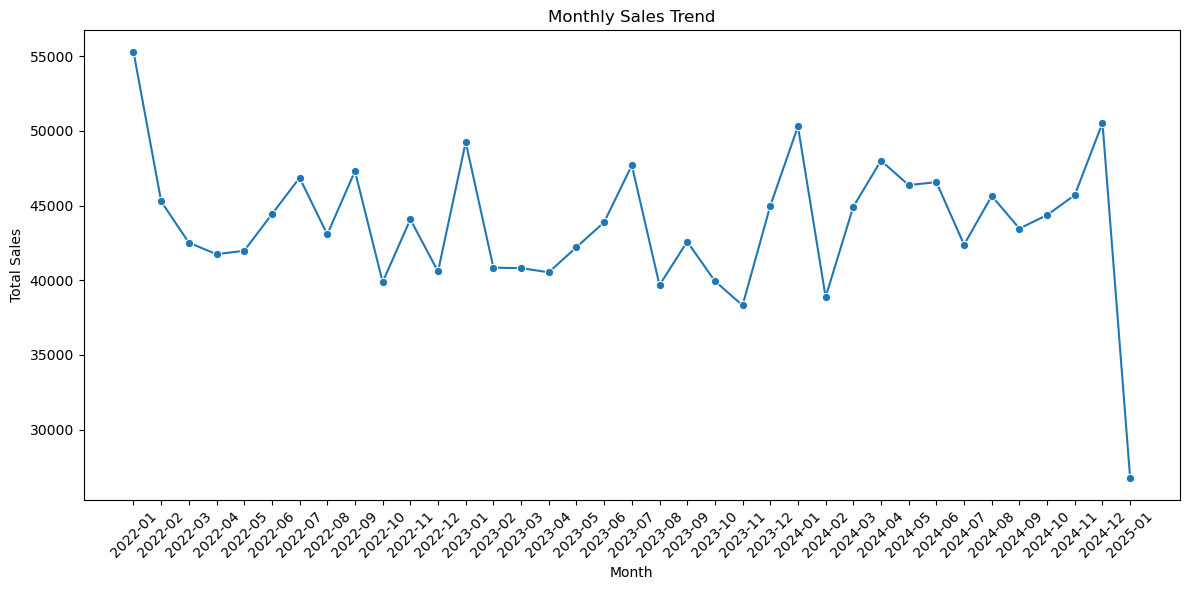

In [55]:
#visualization
#monthly sales trend
plt.figure(figsize=(12,6))

sns.lineplot(
    data=monthly_report,
    x="Month",
    y="Total_Sales",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

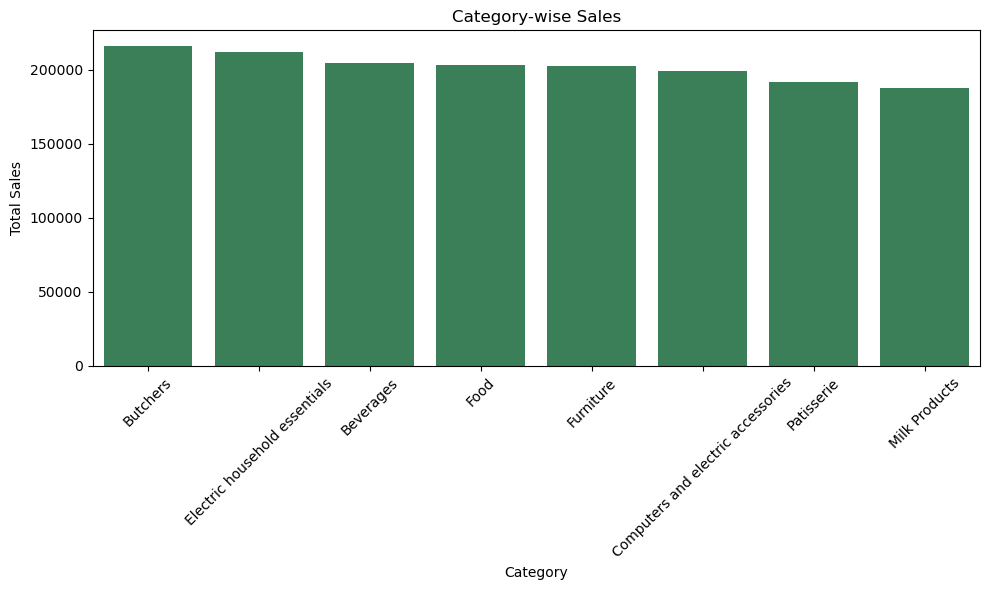

In [65]:
#category wise sales
plt.figure(figsize=(10 , 6))

sns.barplot(data = category_report , x="Category" , y="Total_Sales" , color = "seagreen")

plt.title("Category-wise Sales")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [67]:
import os

# Folder where you want to save the files
output_folder = r"C:\Users\91957\Documents\INTERNSHIPS\Thirnex\output"

# Create folder if it does not exist
os.makedirs(output_folder, exist_ok=True)

# Export cleaned dataset
df_clean.to_csv(
    os.path.join(output_folder, "cleaned_retail_sales.csv"),
    index=False
)

# Export reports
monthly_report.to_csv(
    os.path.join(output_folder, "monthly_sales_report.csv"),
    index=False
)

category_report.to_csv(
    os.path.join(output_folder, "category_sales_report.csv"),
    index=False
)

payment_report.to_csv(
    os.path.join(output_folder, "payment_method_report.csv"),
    index=False
)

print("All files saved successfully!")

All files saved successfully!


In [69]:
output_folder = "output"

In [71]:
import pandas as pd
import numpy as np
import os

def automate_data_cleaning(input_file, output_folder="output"):

    # Step 1: Load dataset
    df = pd.read_csv(input_file)

    print("Original Dataset Shape:", df.shape)

    # Step 2: Remove duplicate records
    df = df.drop_duplicates()

    # Step 3: Clean text columns
    text_columns = [
        "Item",
        "Category",
        "Payment Method",
        "Location",
        "Discount Applied"
    ]

    for col in text_columns:
        df[col] = df[col].astype("string").str.strip()

    # Replace empty strings with missing values
    df = df.replace(r"^\s*$", np.nan, regex=True)

    # Step 4: Convert date column
    df["Transaction Date"] = pd.to_datetime(
        df["Transaction Date"],
        errors="coerce"
    )

    # Step 5: Convert numeric columns
    numeric_columns = [
        "Price Per Unit",
        "Quantity",
        "Total Spent"
    ]

    for col in numeric_columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Step 6: Handle missing values
    df["Item"] = df["Item"].fillna("Unknown")

    df["Discount Applied"] = (
        df["Discount Applied"].fillna("Unknown")
    )

    for col in numeric_columns:
        median_value = df[col].median()

        if pd.notna(median_value):
            df[col] = df[col].fillna(median_value)

    # Remove rows with invalid dates
    df = df.dropna(subset=["Transaction Date"])

    # Step 7: Calculate KPIs
    total_revenue = df["Total Spent"].sum()
    total_transactions = df["Transaction ID"].nunique()
    total_quantity = df["Quantity"].sum()
    average_transaction = df["Total Spent"].mean()

    print("\n--- KPI REPORT ---")
    print("Total Revenue:", round(total_revenue, 2))
    print("Total Transactions:", total_transactions)
    print("Total Quantity Sold:", total_quantity)
    print("Average Transaction Value:", round(average_transaction, 2))

    # Step 8: Generate monthly report
    df["Month"] = df["Transaction Date"].dt.to_period("M")

    monthly_report = (
        df.groupby("Month")
        .agg(
            Total_Sales=("Total Spent", "sum"),
            Total_Quantity=("Quantity", "sum"),
            Transactions=("Transaction ID", "nunique")
        )
        .reset_index()
    )

    monthly_report["Month"] = monthly_report["Month"].astype(str)

    # Step 9: Generate category report
    category_report = (
        df.groupby("Category")
        .agg(
            Total_Sales=("Total Spent", "sum"),
            Total_Quantity=("Quantity", "sum"),
            Transactions=("Transaction ID", "nunique")
        )
        .reset_index()
        .sort_values("Total_Sales", ascending=False)
    )

    # Step 10: Generate payment report
    payment_report = (
        df.groupby("Payment Method")
        .agg(
            Total_Sales=("Total Spent", "sum"),
            Transactions=("Transaction ID", "nunique")
        )
        .reset_index()
    )

    # Step 11: Create output folder
    os.makedirs(output_folder, exist_ok=True)

    # Step 12: Export cleaned dataset
    df.to_csv(
        os.path.join(output_folder, "cleaned_retail_sales.csv"),
        index=False
    )

    # Export reports
    monthly_report.to_csv(
        os.path.join(output_folder, "monthly_sales_report.csv"),
        index=False
    )

    category_report.to_csv(
        os.path.join(output_folder, "category_sales_report.csv"),
        index=False
    )

    payment_report.to_csv(
        os.path.join(output_folder, "payment_method_report.csv"),
        index=False
    )

    # Export KPI report
    kpi_report = pd.DataFrame({
        "Metric": [
            "Total Revenue",
            "Total Transactions",
            "Total Quantity Sold",
            "Average Transaction Value"
        ],
        "Value": [
            total_revenue,
            total_transactions,
            total_quantity,
            average_transaction
        ]
    })

    kpi_report.to_csv(
        os.path.join(output_folder, "kpi_report.csv"),
        index=False
    )

    print("\nAll reports generated successfully!")
    print("Files saved in:", os.path.abspath(output_folder))

    return df, monthly_report, category_report, payment_report

In [73]:
df_clean, monthly_report, category_report, payment_report = (
    automate_data_cleaning("retail_store_sales.csv")
)

Original Dataset Shape: (12575, 11)

--- KPI REPORT ---
Total Revenue: 1617605.0
Total Transactions: 12575
Total Quantity Sold: 69900.0
Average Transaction Value: 128.64

All reports generated successfully!
Files saved in: C:\Users\91957\Documents\INTERNSHIPS\Thirnex\output
